<a href="https://colab.research.google.com/github/Joy-Kimani/slm-arm64-benchmark/blob/main/02_train_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Train a 70M English SLM from scratch

This notebook builds a Llama-style small language model (RMSNorm, rotary position embeddings, SwiGLU) of about 70 million parameters and trains it on TinyStories. Run the "01_data_prep" notebook first.

**NOTE**: The training saves a checkpoint to Google Drive every few steps. If Colab disconnects, run the notebook again from the top and it carries on from the last checkpoint.

## Step 1: Mount Google Drive and copy the data

Reading the bin files straight from Drive is slow, so we copy them to the local Colab disk first.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

out_dir = '/content/drive/MyDrive/slm70m'

Mounted at /content/drive


In [ ]:
!cp {out_dir}/train.bin {out_dir}/validation.bin /content/

In [ ]:
import os
import json
import math
import time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from dataclasses import dataclass
from contextlib import nullcontext
from tqdm.auto import tqdm

meta = json.load(open(os.path.join(out_dir, 'meta.json')))
print(meta)

{'vocab_size': 16000, 'train_tokens': 463152428, 'val_tokens': 4655638, 'val_bytes_per_token': 4.127973437797355}


## Step 2: Define the training configuration

Each optimizer step uses 32 x 256 x 8 = 65,536 tokens. 5000 steps is about 330M tokens.

In [ ]:
learning_rate = 6e-4
min_lr = 6e-5
max_steps = 5000              # optimizer steps
warmup_steps = 200
batch_size = 32
block_size = 256              # context window
gradient_accumulation_steps = 8
eval_interval = 250
eval_iters = 50

device = "cuda" if torch.cuda.is_available() else "cpu"
device_type = 'cuda' if 'cuda' in device else 'cpu'

# the T4 has no real bfloat16, so only use it on newer GPUs
dtype = 'bfloat16' if device_type == 'cuda' and torch.cuda.get_device_capability()[0] >= 8 else 'float16'
ptdtype = {'float32': torch.float32, 'bfloat16': torch.bfloat16, 'float16': torch.float16}[dtype]

ctx = nullcontext() if device_type == 'cpu' else torch.amp.autocast(device_type=device_type, dtype=ptdtype)

torch.set_default_device(device)
torch.manual_seed(42)

## Step 3: Create Input-Output batches for the dataset

In [ ]:
def get_batch(split):
    # recreate np.memmap every batch to avoid a memory leak
    if split == 'train':
        data = np.memmap('/content/train.bin', dtype=np.uint16, mode='r')
    else:
        data = np.memmap('/content/validation.bin', dtype=np.uint16, mode='r')
    ix = torch.randint(len(data) - block_size, (batch_size,))
    x = torch.stack([torch.from_numpy((data[i:i+block_size]).astype(np.int64)) for i in ix])
    y = torch.stack([torch.from_numpy((data[i+1:i+1+block_size]).astype(np.int64)) for i in ix])
    if device_type == 'cuda':
        x, y = x.pin_memory().to(device, non_blocking=True), y.pin_memory().to(device, non_blocking=True)
    else:
        x, y = x.to(device), y.to(device)
    return x, y

## Step 4: Define the SLM Model Architecture

The layer names (embed_tokens, self_attn, q_proj, gate_proj and so on) follow the Hugging Face Llama naming. That way the saved weights can be exported for llama.cpp later without renaming anything.

In [ ]:
class RMSNorm(nn.Module):
    def __init__(self, ndim, eps=1e-5):
        super().__init__()
        self.weight = nn.Parameter(torch.ones(ndim))
        self.eps = eps

    def forward(self, x):
        x32 = x.float()
        x32 = x32 * torch.rsqrt(x32.pow(2).mean(-1, keepdim=True) + self.eps)
        return self.weight * x32.type_as(x)


def rope_cache(head_dim, block_size, theta=10000.0):
    inv_freq = 1.0 / (theta ** (torch.arange(0, head_dim, 2).float() / head_dim))
    t = torch.arange(block_size).float()
    freqs = torch.outer(t, inv_freq)
    emb = torch.cat((freqs, freqs), dim=-1)
    return emb.cos(), emb.sin()

def rotate_half(x):
    half = x.shape[-1] // 2
    return torch.cat((-x[..., half:], x[..., :half]), dim=-1)

def apply_rope(x, cos, sin):
    return x * cos.to(x.dtype) + rotate_half(x) * sin.to(x.dtype)


class CausalSelfAttention(nn.Module):
    def __init__(self, config):
        super().__init__()
        assert config.n_embd % config.n_head == 0
        self.n_head = config.n_head
        self.head_dim = config.n_embd // config.n_head
        self.q_proj = nn.Linear(config.n_embd, config.n_embd, bias=False)
        self.k_proj = nn.Linear(config.n_embd, config.n_embd, bias=False)
        self.v_proj = nn.Linear(config.n_embd, config.n_embd, bias=False)
        self.o_proj = nn.Linear(config.n_embd, config.n_embd, bias=False)
        cos, sin = rope_cache(self.head_dim, config.block_size)
        self.register_buffer('cos', cos, persistent=False)
        self.register_buffer('sin', sin, persistent=False)

    def forward(self, x):
        B, T, C = x.size()
        q = self.q_proj(x).view(B, T, self.n_head, self.head_dim).transpose(1, 2)
        k = self.k_proj(x).view(B, T, self.n_head, self.head_dim).transpose(1, 2)
        v = self.v_proj(x).view(B, T, self.n_head, self.head_dim).transpose(1, 2)

        q = apply_rope(q, self.cos[:T], self.sin[:T])
        k = apply_rope(k, self.cos[:T], self.sin[:T])

        y = F.scaled_dot_product_attention(q, k, v, is_causal=True)
        y = y.transpose(1, 2).contiguous().view(B, T, C)
        return self.o_proj(y)


class MLP(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.gate_proj = nn.Linear(config.n_embd, config.n_hidden, bias=False)
        self.up_proj = nn.Linear(config.n_embd, config.n_hidden, bias=False)
        self.down_proj = nn.Linear(config.n_hidden, config.n_embd, bias=False)

    def forward(self, x):
        return self.down_proj(F.silu(self.gate_proj(x)) * self.up_proj(x))


class Block(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.input_layernorm = RMSNorm(config.n_embd)
        self.self_attn = CausalSelfAttention(config)
        self.post_attention_layernorm = RMSNorm(config.n_embd)
        self.mlp = MLP(config)

    def forward(self, x):
        x = x + self.self_attn(self.input_layernorm(x))
        x = x + self.mlp(self.post_attention_layernorm(x))
        return x


@dataclass
class GPTConfig:
    block_size: int
    vocab_size: int
    n_layer: int
    n_head: int
    n_embd: int
    n_hidden: int


class GPT(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.config = config
        self.model = nn.ModuleDict(dict(
            embed_tokens=nn.Embedding(config.vocab_size, config.n_embd),
            layers=nn.ModuleList([Block(config) for _ in range(config.n_layer)]),
            norm=RMSNorm(config.n_embd),
        ))
        self.lm_head = nn.Linear(config.n_embd, config.vocab_size, bias=False)
        self.model.embed_tokens.weight = self.lm_head.weight  # weight tying

        self.apply(self._init_weights)
        for pn, p in self.named_parameters():
            if pn.endswith('o_proj.weight') or pn.endswith('down_proj.weight'):
                nn.init.normal_(p, mean=0.0, std=0.02 / math.sqrt(2 * config.n_layer))

    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)
        elif isinstance(module, nn.Embedding):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def forward(self, idx, targets=None):
        b, t = idx.size()
        assert t <= self.config.block_size

        x = self.model.embed_tokens(idx)
        for block in self.model.layers:
            x = block(x)
        x = self.model.norm(x)

        if targets is not None:
            logits = self.lm_head(x)
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1), ignore_index=-1)
            return logits, loss
        else:
            logits = self.lm_head(x[:, [-1], :])
            return logits, None

    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=1.0, top_k=None):
        for _ in range(max_new_tokens):
            idx_cond = idx if idx.size(1) <= self.config.block_size else idx[:, -self.config.block_size:]
            logits, _ = self(idx_cond)
            logits = logits[:, -1, :] / temperature
            if top_k is not None:
                v, _ = torch.topk(logits, min(top_k, logits.size(-1)))
                logits[logits < v[:, [-1]]] = -float('Inf')
            probs = F.softmax(logits, dim=-1)
            idx_next = torch.multinomial(probs, num_samples=1)
            idx = torch.cat((idx, idx_next), dim=1)
        return idx

In [ ]:
config = GPTConfig(
    vocab_size=meta['vocab_size'],
    block_size=block_size,
    n_layer=12,
    n_head=10,
    n_embd=640,
    n_hidden=1728,
)

model = GPT(config)

n_params = sum(p.numel() for p in model.parameters())
print(f"{n_params/1e6:.1f}M parameters")

69.7M parameters


## Step 5: Define the loss function

Besides the loss we also print bits per byte on the validation set. Bits per byte does not depend on the tokenizer, so we can compare this model with ones that use a different vocabulary later.

In [ ]:
def estimate_loss(model):
    out = {}
    model.eval()
    with torch.inference_mode():
        for split in ['train', 'val']:
            losses = torch.zeros(eval_iters)
            for k in range(eval_iters):
                X, Y = get_batch(split)
                with ctx:
                    logits, loss = model(X, Y)
                losses[k] = loss.item()
            out[split] = losses.mean().item()
    model.train()
    return out

def bits_per_byte(loss):
    return loss / math.log(2) / meta['val_bytes_per_token']

## Step 6: Define the optimizer and learning rate schedule

Weight decay is only applied to the weight matrices, not to the norm weights.

In [ ]:
from torch.optim.lr_scheduler import LinearLR, SequentialLR, CosineAnnealingLR

decay_params = [p for p in model.parameters() if p.dim() >= 2]
nodecay_params = [p for p in model.parameters() if p.dim() < 2]

optimizer = torch.optim.AdamW([
    {'params': decay_params, 'weight_decay': 0.1},
    {'params': nodecay_params, 'weight_decay': 0.0},
], lr=learning_rate, betas=(0.9, 0.95), eps=1e-8)

scheduler_warmup = LinearLR(optimizer, start_factor=0.01, total_iters=warmup_steps)
scheduler_decay = CosineAnnealingLR(optimizer, T_max=max_steps - warmup_steps, eta_min=min_lr)
scheduler = SequentialLR(optimizer, schedulers=[scheduler_warmup, scheduler_decay], milestones=[warmup_steps])

scaler = torch.amp.GradScaler('cuda', enabled=(dtype == 'float16'))

## Step 7: Resume from a checkpoint if there is one

In [ ]:
ckpt_path = os.path.join(out_dir, 'ckpt.pt')
best_model_params_path = os.path.join(out_dir, 'best_model_params.pt')

step = 0
best_val_loss = float('inf')
train_loss_list, validation_loss_list = [], []

if os.path.exists(ckpt_path):
    ckpt = torch.load(ckpt_path, map_location=device, weights_only=False)
    model.load_state_dict(ckpt['model'])
    optimizer.load_state_dict(ckpt['optimizer'])
    scheduler.load_state_dict(ckpt['scheduler'])
    scaler.load_state_dict(ckpt['scaler'])
    step = ckpt['step']
    best_val_loss = ckpt['best_val_loss']
    train_loss_list = ckpt['train_loss_list']
    validation_loss_list = ckpt['validation_loss_list']
    print(f"resumed from step {step}")

## Step 8: Pre-train the SLM

In [12]:
model = model.to(device)
model.train()
tokens_per_step = batch_size * block_size * gradient_accumulation_steps

pbar = tqdm(total=max_steps, initial=step)
while step < max_steps:
    t0 = time.time()

    for micro_step in range(gradient_accumulation_steps):
        X, y = get_batch("train")
        with ctx:
            logits, loss = model(X, y)
            loss = loss / gradient_accumulation_steps
        scaler.scale(loss).backward()

    scaler.unscale_(optimizer)
    torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
    scaler.step(optimizer)
    scaler.update()
    optimizer.zero_grad(set_to_none=True)
    scheduler.step()

    step += 1
    pbar.update(1)
    pbar.set_postfix(tok_per_s=int(tokens_per_step / (time.time() - t0)))

    if step % eval_interval == 0:
        losses = estimate_loss(model)
        print(f"Step {step}: train loss {losses['train']:.4f}, val loss {losses['val']:.4f}, val bits/byte {bits_per_byte(losses['val']):.4f}")
        print(f"The current learning rate: {optimizer.param_groups[0]['lr']:.6f}")
        train_loss_list += [losses['train']]
        validation_loss_list += [losses['val']]

        if losses['val'] < best_val_loss:
            best_val_loss = losses['val']
            torch.save(model.state_dict(), best_model_params_path)

        torch.save({
            'model': model.state_dict(),
            'optimizer': optimizer.state_dict(),
            'scheduler': scheduler.state_dict(),
            'scaler': scaler.state_dict(),
            'step': step,
            'best_val_loss': best_val_loss,
            'train_loss_list': train_loss_list,
            'validation_loss_list': validation_loss_list,
        }, ckpt_path)

 47%|####7     | 2372/5000 [00:00<?, ?it/s]

Step 2500: train loss 1.5036, val loss 1.5145, val bits/byte 0.5293
The current learning rate: 0.000348
Step 2750: train loss 1.4778, val loss 1.4924, val bits/byte 0.5216
The current learning rate: 0.000304
Step 3000: train loss 1.4662, val loss 1.4856, val bits/byte 0.5192
The current learning rate: 0.000260
Step 3250: train loss 1.4494, val loss 1.4590, val bits/byte 0.5099
The current learning rate: 0.000219
Step 3500: train loss 1.4172, val loss 1.4600, val bits/byte 0.5103
The current learning rate: 0.000180
Step 3750: train loss 1.3996, val loss 1.4420, val bits/byte 0.5040
The current learning rate: 0.000145
Step 4000: train loss 1.4001, val loss 1.4289, val bits/byte 0.4994
The current learning rate: 0.000116
Step 4250: train loss 1.3789, val loss 1.4171, val bits/byte 0.4953
The current learning rate: 0.000092
Step 4500: train loss 1.4018, val loss 1.3918, val bits/byte 0.4864
The current learning rate: 0.000074
Step 4750: train loss 1.3649, val loss 1.4005, val bits/byte 0.4

## Step 9: Plot the SLM Loss Function

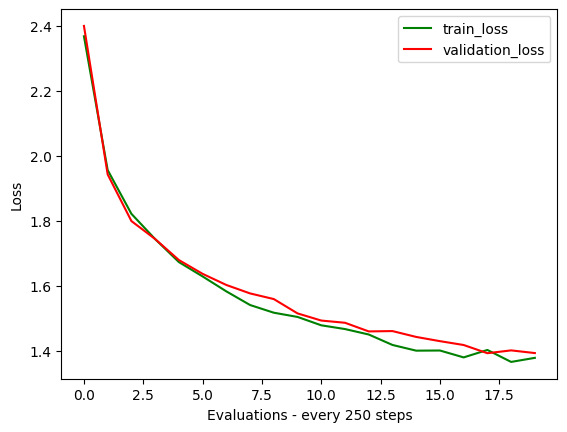

In [13]:
import matplotlib.pyplot as plt

plt.plot(train_loss_list, 'g', label='train_loss')
plt.plot(validation_loss_list, 'r', label='validation_loss')
plt.xlabel(f"Evaluations - every {eval_interval} steps")
plt.ylabel("Loss")
plt.legend()
plt.show()

## Step 10: Run SLM Inference on our trained model

In [14]:
!pip install tokenizers

In [15]:
from tokenizers import Tokenizer

tokenizer = Tokenizer.from_file(os.path.join(out_dir, 'tokenizer.json'))

model = GPT(config)
model.load_state_dict(torch.load(best_model_params_path, map_location=torch.device(device)))
model.eval()

GPT(
  (model): ModuleDict(
    (embed_tokens): Embedding(16000, 640)
    (layers): ModuleList(
      (0-11): 12 x Block(
        (input_layernorm): RMSNorm()
        (self_attn): CausalSelfAttention(
          (q_proj): Linear(in_features=640, out_features=640, bias=False)
          (k_proj): Linear(in_features=640, out_features=640, bias=False)
          (v_proj): Linear(in_features=640, out_features=640, bias=False)
          (o_proj): Linear(in_features=640, out_features=640, bias=False)
        )
        (post_attention_layernorm): RMSNorm()
        (mlp): MLP(
          (gate_proj): Linear(in_features=640, out_features=1728, bias=False)
          (up_proj): Linear(in_features=640, out_features=1728, bias=False)
          (down_proj): Linear(in_features=1728, out_features=640, bias=False)
        )
      )
    )
    (norm): RMSNorm()
  )
  (lm_head): Linear(in_features=640, out_features=16000, bias=False)
)

In [16]:
sentence = "Once upon a time there was a pumpkin."
context = torch.tensor(tokenizer.encode(sentence).ids).unsqueeze(dim=0)
y = model.generate(context, 200, temperature=0.8, top_k=50)
print(tokenizer.decode(y.squeeze().tolist()))

Once upon a time there was a pumpkin. It was bright green and very tasty. One day, a little girl wanted to pick the pumpkin. She was very happy and she ran outside. 

When she got to the pumpkin, she saw it was very dirty. She started to cry. She didn't want to ruin the pumpkin. 

But then she heard a voice. "Why are you so sad?" it asked. She looked up and saw a friendly face. It was a friendly face and it said, "Let me help you! Let's find some water and clean the pumpkin." 

So the little girl and the friendly face searched around the pumpkin. After a while, they found some water and the pumpkin was clean and shiny once again. 

The little girl was very happy and hugged the pumpkin. From then on, she made sure to take care of the pumpkin and it stayed nice and healthy. The end.Mom and Jack were walking through the park. Jack saw something very interesting. It was a


In [17]:
sentence = "A little girl went to the woods"
context = torch.tensor(tokenizer.encode(sentence).ids).unsqueeze(dim=0)
y = model.generate(context, 200, temperature=0.8, top_k=50)
print(tokenizer.decode(y.squeeze().tolist()))

A little girl went to the woods to find a special creature. She found a small, hidden creature! It was a bear! The bear made a noise and the girl was scared.

The bear said, "Don't be scared. I am your friend." The girl was surprised. The bear said, "I want to encourage you. You can do it!"

So the girl and the bear went on an adventure together. They explored the woods, saw lots of interesting things. The girl was no longer scared, and the bear was right there with her. 

The bear was very happy to have a friend. He encouraged her to explore more of the forest and to one day go back.Once upon a time there was a little girl named Molly. She was three years old and loved to explore. One day, Molly was playing in the garden when she found a big, round radish. She picked it up and said, "What is this?" She was curious so she tried to open it,
